# 07 · Publication figures

All figures are drawn from the result tables written by notebooks 01–06; no estimate is computed or edited here. Every figure is saved as vector PDF, 600 dpi PNG and LZW-compressed TIFF, together with the data it plots (`../results/figures/data/`).

**Main figures.** Fig 1 sets the change in tactic use beside the change in pairing (2008–2018 against 2021–2024); Fig 2 shows which tactics kept company over the full period; Fig 3 shows that the same affinities and avoidances recurred every year; Fig 4 locates the years and pairs where the pattern departed. Supplementary figures S1–S10 follow in the order they are cited.

**Style.** One style for the paper: Arial, three font sizes (8/7/6 pt), Okabe–Ito colours with one meaning each (blue = N2, the primary reference; vermillion = N1; green = N2 clean; other references in SI; dark grey = tactic shares), purple = excess and orange = deficit co-occurrence (`PuOr`, centred at zero), red/blue for frequency change (`RdBu_r`, centred at zero), filled markers = beyond sampling noise, ratios on log axes labelled as fold changes, bold panel letters, units on every axis, white background. Captions carry the context.

S9 Fig (b) shows the relative reduction in model discrepancy. The raw deviance and dispersion-adjusted Pearson measures use the archived column names `frequency_share_raw` and `frequency_share_dispersion_floor`.

In [1]:
import os, json, itertools
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import TwoSlopeNorm

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
TAB = ROOT / "results" / "tables"; AGG = ROOT / "results" / "aggregates"
FIG = ROOT / "results" / "figures"; FDATA = FIG / "data"; FDATA.mkdir(parents=True, exist_ok=True)
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 6, "ytick.labelsize": 6, "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.facecolor": "white", "figure.facecolor": "white", "legend.frameon": False})
OI = {"blue": "#0072B2", "vermillion": "#D55E00", "green": "#009E73", "sky": "#56B4E9", "orange": "#E69F00",
      "purple": "#CC79A7", "yellow": "#F0E442", "black": "#000000", "grey": "#8C8C8C"}
REF_COLOR = {"N2": OI["blue"], "N1": OI["vermillion"], "N2_clean": OI["green"], "N2_allmedia": OI["purple"],
             "N2_order": OI["sky"], "N1_k2": OI["orange"]}
REF_LABEL = {"N2": "Context and field (N2)", "N1": "Month (N1)", "N2_clean": "N2, generic codes removed",
             "N2_allmedia": "N2, all media", "N2_order": "N2, order preserved", "N1_k2": "N1, two-tactic actions"}
YEARS = np.arange(2008, 2025)
PAIRS = np.array(list(itertools.combinations(range(1, 36), 2)))
dic = pd.read_csv(TAB / "tactic_dictionary.csv").set_index("code")
FAM_ORDER = ["A Peaceful I", "B Peaceful II", "C Artistic", "D Disruptive", "E Self-destructive", "F Violent"]
FAM_BOUNDS = [6, 14, 17, 24, 26]          # last code of families A-E
SHORT = {5: "Petition or fund collection", 7: "Press conference", 8: "Assembly or debate", 15: "Performance (participants)",
         16: "Performance (artists)", 23: "Interrupting authorities", 26: "Self-endangering act", 32: "Clash with counter-protesters",
         33: "Attack on police", 34: "Attack on bystanders", 35: "Hostage taking"}
short = lambda c: SHORT.get(int(c), dic.loc[int(c), "label_en"])

def panel_letter(ax, letter, x=-0.14, y=1.03):
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=10, fontweight="bold", va="bottom", ha="left")

def layout_problems(fig):
    # render-then-verify: text that overlaps other text, crosses a spine or leaves the canvas
    fig.canvas.draw(); r = fig.canvas.get_renderer()
    pool = {t for ax in fig.axes for axis in (ax.xaxis, ax.yaxis) for tick in axis.majorTicks + axis.minorTicks for t in (tick.label1, tick.label2)}
    own = {ax: set(ax.get_xticklabels(which="both") + ax.get_yticklabels(which="both")) for ax in fig.axes}
    inside = lambda axis, tick: min(axis.get_view_interval()) - 1e-9 <= tick.get_loc() <= max(axis.get_view_interval()) + 1e-9
    active = {t for ax in fig.axes for axis in (ax.xaxis, ax.yaxis) for tick in axis.get_major_ticks() + axis.get_minor_ticks()
              if inside(axis, tick) for t in (tick.label1, tick.label2) if t in own[ax]}
    texts = [(t, t.get_window_extent(r)) for t in fig.findobj(mpl.text.Text)
             if t.get_visible() and t.get_text().strip() and (t not in pool or t in active)]
    spines = [(s, s.get_window_extent(r)) for ax in fig.axes for s in ax.spines.values() if s.get_visible()]
    probs = [f"{a.get_text()[:30]!r} overlaps {b.get_text()[:30]!r}" for i, (a, ba) in enumerate(texts) for b, bb in texts[i + 1:] if ba.overlaps(bb)]
    probs += [f"{t.get_text()[:30]!r} crosses a spine" for t, bt in texts for s, bs in spines if bt.overlaps(bs) and t not in own[s.axes]]
    probs += [f"{t.get_text()[:30]!r} leaves the canvas" for t, bt in texts
              if bt.x0 < fig.bbox.x0 or bt.y0 < fig.bbox.y0 or bt.x1 > fig.bbox.x1 or bt.y1 > fig.bbox.y1]
    return probs

def export_source_table(frame, name, index=False):
    display(frame)
    frame.to_csv(FDATA / name, index=index)

def save(fig, name):
    probs = layout_problems(fig)
    print(name, "layout check:", "ok" if not probs else probs)
    display(fig)
    for ext, kw in [("pdf", {}), ("png", {"dpi": 600}), ("tiff", {"dpi": 600, "pil_kwargs": {"compression": "tiff_lzw"}})]:
        fig.savefig(FIG / f"{name}.{ext}", **kw)
    plt.close(fig)
    print("saved", name)

TACTIC_GREY = "#4D4D4D"
FOLD = {-6: "1/64", -5: "1/32", -4: "1/16", -3: "1/8", -2: "1/4", -1: "1/2", 0: "1", 1: "2", 2: "4", 3: "8", 4: "16", 5: "32"}
def fold_axis(axis, lo, hi, step=1):
    # log2 axes labelled as fold changes
    ticks = [t for t in FOLD if lo <= t <= hi and t % step == 0]
    axis.set_ticks(ticks, [FOLD[t] for t in ticks])


## Fig 1 · Tactic use shifted sharply, but tactics kept the same company

,18,19,10,29,27,30
year,,,,,,
2008,0.339454,0.166253,0.169231,0.003474,0.010918,0.018859
2009,0.331219,0.064834,0.190275,0.000705,0.019732,0.026779
2010,0.243924,0.055556,0.281250,0.000000,0.019965,0.019097
2011,0.165183,0.180766,0.200801,0.005343,0.020481,0.015583
2012,0.131561,0.125426,0.134969,0.006817,0.049761,0.044990
2013,0.295306,0.092249,0.188865,0.002183,0.035480,0.030568
2014,0.279109,0.068524,0.176045,0.000557,0.042897,0.037883
2015,0.212025,0.067247,0.147152,0.002373,0.067247,0.027690
2016,0.227473,0.091997,0.207309,0.003151,0.083176,0.019534


,code,label,family,actions_2008_2018,actions_2021_2024,share_2008_2018,share_2021_2024,log2_change,lo,hi,beyond_noise
0,1,March,A Peaceful I,4419,802,0.256055,0.162942,-0.651361,-0.855633,-0.455844,True
1,2,Static demonstration,A Peaceful I,3644,1504,0.211148,0.305567,0.533512,0.414874,0.650170,True
2,3,Rally with speakers,A Peaceful I,518,80,0.030015,0.016254,-0.877335,-1.451125,-0.439118,True
3,4,Caravan,A Peaceful I,258,99,0.014950,0.020114,0.432553,-0.132619,0.973236,False
4,5,Petition or fund collection,A Peaceful I,495,158,0.028682,0.032101,0.165547,-0.154404,0.441720,False
5,7,Press conference or statement,B Peaceful II,41,6,0.002376,0.001219,-0.864651,-2.371717,0.248499,False
6,8,Assembly or open debate,B Peaceful II,35,4,0.002028,0.000813,-1.169873,-2.971697,-0.036360,True
7,9,Commemoration,B Peaceful II,274,175,0.015877,0.035555,1.164614,0.376114,1.845005,True
8,10,Chants or slogans,B Peaceful II,3608,2224,0.209062,0.451849,1.112031,1.004132,1.217594,True
9,11,Boycott,B Peaceful II,28,40,0.001622,0.008127,2.316909,-0.044135,4.092018,False


,reference,code_i,code_j,label_i,label_j,observed_2008_2018,observed_2021_2024,expected_2008_2018,expected_2021_2024,share_change_observed,share_change_expected,association_change,lo,hi,beyond_noise
0,N2,1,2,March,Static demonstration,226.0,57.0,379.973973,103.396396,-0.819088,-0.713863,-0.105225,-0.571824,0.320840,False
1,N2,1,3,March,Rally with speakers,390.0,49.0,129.920921,15.286286,-1.821033,-1.887642,0.066609,-0.632964,0.581757,False
2,N2,1,4,March,Caravan,41.0,13.0,34.449449,6.608609,-0.461363,-1.138841,0.677479,-0.352382,1.485964,False
3,N2,1,5,March,Petition or fund collection,218.0,60.0,99.193193,27.331331,-0.693837,-0.681996,-0.011841,-0.416317,0.383717,False
4,N2,1,9,March,Commemoration,81.0,83.0,35.534535,21.262262,1.193765,0.431238,0.762528,-0.124873,1.433384,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,N2,27,34,Arson,Attack on bystanders,57.0,95.0,37.212212,72.332332,1.890728,2.108337,-0.217608,-0.662596,0.197901,False
104,N2,28,30,Property destruction,Explosives or firearms,79.0,47.0,50.822823,35.440440,0.415762,0.644797,-0.229035,-0.722868,0.257351,False
105,N2,28,33,Property destruction,Attack on police or security forces,200.0,84.0,115.319319,54.118118,-0.087790,0.074365,-0.162155,-0.509398,0.158398,False
106,N2,30,33,Explosives or firearms,Attack on police or security forces,241.0,157.0,117.390390,84.523524,0.542118,0.687277,-0.145159,-0.428488,0.140659,False


Fig1 layout check: ok


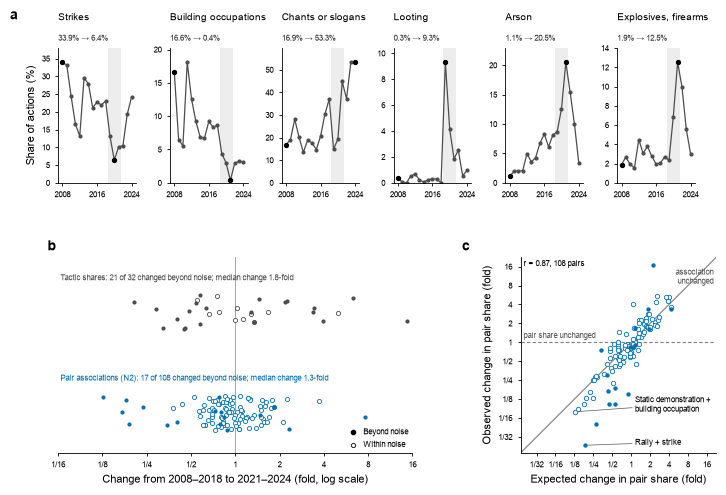

saved Fig1


In [2]:
share = pd.read_csv(TAB / "tactic_share_by_year.csv").set_index("year"); share.columns = share.columns.astype(int)
ctac = pd.read_csv(TAB / "change_tactic_shares_blocks.csv")
cpair_all = pd.read_csv(TAB / "change_pairs_blocks.csv"); cpair = cpair_all[cpair_all.reference == "N2"]
csum = pd.read_csv(TAB / "change_summary.csv").set_index("reference")
SIX = [18, 19, 10, 29, 27, 30]                      # the six shifts described in the Results
NAME6 = {18: "Strikes", 19: "Building occupations", 10: "Chants or slogans", 29: "Looting", 27: "Arson", 30: "Explosives, firearms"}
EXT6 = {18: (2020, "min"), 19: (2021, "min"), 10: (2024, "max"), 29: (2019, "max"), 27: (2021, "max"), 30: (2021, "max")}
export_source_table(share[SIX], "fig1a_tactic_shares.csv", index=True)
export_source_table(ctac, "fig1b_tactic_changes.csv"); export_source_table(cpair, "fig1bc_pair_changes_N2.csv")

fig = plt.figure(figsize=(7.5, 5.0))
outer = GridSpec(2, 1, figure=fig, height_ratios=[1, 1.45], hspace=0.45, left=0.075, right=0.985, top=0.9, bottom=0.09)
top = outer[0].subgridspec(1, 7, width_ratios=[1] * 6 + [0.15], wspace=0.5)
for k, c in enumerate(SIX):
    ax = fig.add_subplot(top[0, k]); s = 100 * share[c]
    ax.axvspan(2018.5, 2021.5, color="#EDEDED", lw=0, zorder=0)
    ax.plot(YEARS, s, "-o", color=TACTIC_GREY, ms=2, lw=0.9, zorder=2)
    ext, kind = EXT6[c]
    assert s[ext] == (s.min() if kind == "min" else s.max())          # the extreme named in the Results
    ax.plot([2008, ext], [s[2008], s[ext]], "o", color="black", ms=2.8, zorder=3)
    ax.set_ylim(0, s.max() * 1.12); ax.set_xlim(2007, 2025); ax.set_xticks([2008, 2016, 2024]); ax.tick_params(axis="x", labelsize=6)
    ax.text(0, 1.19, NAME6[c], transform=ax.transAxes, fontsize=7, ha="left", va="bottom")
    ax.text(0, 1.04, f"{s[2008]:.1f}% \u2192 {s[ext]:.1f}%", transform=ax.transAxes, fontsize=6, ha="left", va="bottom", color="#333333")
    if k == 0:
        ax.set_ylabel("Share of actions (%)"); panel_letter(ax, "a", x=-0.62, y=1.19)
gs_b = outer[1].subgridspec(1, 2, width_ratios=[1.45, 1], wspace=0.28)
ax = fig.add_subplot(gs_b[0, 0])
rows = [("Tactic shares", ctac.log2_change.to_numpy(), ctac.beyond_noise.to_numpy(), TACTIC_GREY, 1.0),
        ("Pair associations (N2)", cpair.association_change.to_numpy(), cpair.beyond_noise.to_numpy(), REF_COLOR["N2"], 0.0)]
jit = np.random.default_rng(7)
for lab, v, beyond, col, yy in rows:
    yj = yy + jit.uniform(-0.17, 0.17, len(v))
    ax.scatter(v[~beyond], yj[~beyond], s=9, facecolor="white", edgecolor=col, lw=0.6, zorder=2)
    ax.scatter(v[beyond], yj[beyond], s=9, color=col, lw=0, zorder=3)
    med = np.median(np.abs(v))
    ax.text(-3.95, yy + 0.3, f"{lab}: {int(beyond.sum())} of {len(v)} changed beyond noise; median change {2 ** med:.1f}-fold",
            fontsize=6, ha="left", va="bottom", color=col)
ax.axvline(0, color=META_GREY if "META_GREY" in globals() else "#999999", lw=0.6, zorder=1)
ax.set_xlim(-4, 4); fold_axis(ax.xaxis, -4, 4); ax.set_ylim(-0.4, 1.55); ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlabel("Change from 2008–2018 to 2021–2024 (fold, log scale)")
ax.scatter([], [], s=9, color="k", label="Beyond noise"); ax.scatter([], [], s=9, facecolor="white", edgecolor="k", lw=0.6, label="Within noise")
ax.legend(loc="lower right", fontsize=6, handletextpad=0.2, borderaxespad=0.1)
panel_letter(ax, "b", x=-0.03, y=1.02)
ax = fig.add_subplot(gs_b[0, 1])
x, y, beyond = cpair.share_change_expected.to_numpy(), cpair.share_change_observed.to_numpy(), cpair.beyond_noise.to_numpy()
lo_c, hi_c = min(x.min(), y.min()) - 0.4, max(x.max(), y.max()) + 0.4
ax.plot([lo_c, hi_c], [lo_c, hi_c], color="#7F7F7F", lw=0.8, zorder=1)
ax.axhline(0, color="#7F7F7F", lw=0.8, ls=(0, (3, 2)), zorder=1)
ax.scatter(x[~beyond], y[~beyond], s=10, facecolor="white", edgecolor=REF_COLOR["N2"], lw=0.6, zorder=2)
ax.scatter(x[beyond], y[beyond], s=10, color=REF_COLOR["N2"], lw=0, zorder=3)
ax.text(hi_c - 0.15, hi_c - 0.55, "association\nunchanged", ha="right", va="top", fontsize=6, color="#5A5A5A")
ax.text(lo_c + 0.15, 0.12, "pair share unchanged", ha="left", va="bottom", fontsize=6, color="#5A5A5A")
s_ = csum.loc["N2"]
ax.text(lo_c + 0.15, hi_c - 0.15, f"r = {s_.r_expected_observed:.2f}, {int(s_.pairs)} pairs", ha="left", va="top", fontsize=6)
for (ci, cj), txt, xyt in [((2, 19), "Static demonstration +\nbuilding occupation", (0.2, -3.3)), ((3, 18), "Rally + strike", (0.2, -5.3))]:
    r_ = cpair[(cpair.code_i == ci) & (cpair.code_j == cj)].iloc[0]
    ax.annotate(txt, (r_.share_change_expected, r_.share_change_observed), xytext=xyt,
                fontsize=6, ha="left", va="center", arrowprops=dict(arrowstyle="-", lw=0.5, color="#5A5A5A", shrinkA=0, shrinkB=2))
ax.set_xlim(lo_c, hi_c); ax.set_ylim(lo_c, hi_c); ax.set_aspect("equal")
fold_axis(ax.xaxis, lo_c, hi_c); fold_axis(ax.yaxis, lo_c, hi_c)
ax.set_xlabel("Expected change in pair share (fold)"); ax.set_ylabel("Observed change in pair share (fold)")
panel_letter(ax, "c", x=-0.3, y=1.02)
save(fig, "Fig1")

## Fig 2 · Which tactics kept company (N2, 2008–2024)

,code_i,code_j,label_i,label_j,family_i,family_j,observed,expected,sd_reference,difference,z,log2_ratio,p_mc_two_sided,q_bh_595,eligible_primary,evaluable
0,1,2,March,Static demonstration,A Peaceful I,A Peaceful I,358,603.436436,18.842766,-245.436436,-13.025500,-0.752424,0.002,0.007580,True,True
1,1,3,March,Rally with speakers,A Peaceful I,A Peaceful I,482,161.609610,10.472684,320.390390,30.592960,1.573559,0.002,0.007580,True,True
2,1,4,March,Caravan,A Peaceful I,A Peaceful I,77,55.748749,6.404058,21.251251,3.318404,0.462375,0.002,0.007580,True,True
3,1,5,March,Petition or fund collection,A Peaceful I,A Peaceful I,312,141.059059,10.351610,170.940941,16.513464,1.142452,0.002,0.007580,True,True
5,1,7,March,Press conference or statement,A Peaceful I,B Peaceful II,13,8.976977,2.503799,4.023023,1.606768,0.510461,0.184,0.384140,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
578,29,34,Looting,Attack on bystanders,F Violent,F Violent,11,14.084084,3.034692,-3.084084,-1.016276,-0.342761,0.400,0.685879,True,True
582,30,33,Explosives or firearms,Attack on police or security forces,F Violent,F Violent,519,260.687688,10.224071,258.312312,25.265114,0.992037,0.002,0.007580,True,True
583,30,34,Explosives or firearms,Attack on bystanders,F Violent,F Violent,171,96.334334,6.478756,74.665666,11.524692,0.824618,0.002,0.007580,True,True
589,32,33,Clashes with counter-protesters,Attack on police or security forces,F Violent,F Violent,20,21.796797,3.508043,-1.796797,-0.512194,-0.121213,0.720,1.000000,True,True


,reference,family_a,family_b,pairs,observed,expected,log2_ratio,z,p_mc
21,N2,A Peaceful I,A Peaceful I,15,1691,1398.563564,0.273842,10.441825,0.002
22,N2,A Peaceful I,B Peaceful II,48,6697,4554.542543,0.556158,54.464230,0.002
23,N2,A Peaceful I,C Artistic,18,1443,936.620621,0.623264,22.795221,0.002
24,N2,A Peaceful I,D Disruptive,42,3562,3534.830831,0.011045,0.751027,0.464
25,N2,A Peaceful I,E Self-destructive,12,75,125.175175,-0.735151,-5.260762,0.002
26,N2,A Peaceful I,F Violent,54,2657,2853.547548,-0.102940,-4.810140,0.002
27,N2,B Peaceful II,B Peaceful II,28,428,421.472472,0.022146,0.422741,0.674
28,N2,B Peaceful II,C Artistic,24,677,673.831832,0.006762,0.171105,0.884
29,N2,B Peaceful II,D Disruptive,56,1892,3568.353353,-0.915167,-47.526414,0.002
30,N2,B Peaceful II,E Self-destructive,16,53,137.769770,-1.369875,-8.929503,0.002


Fig2 layout check: ok


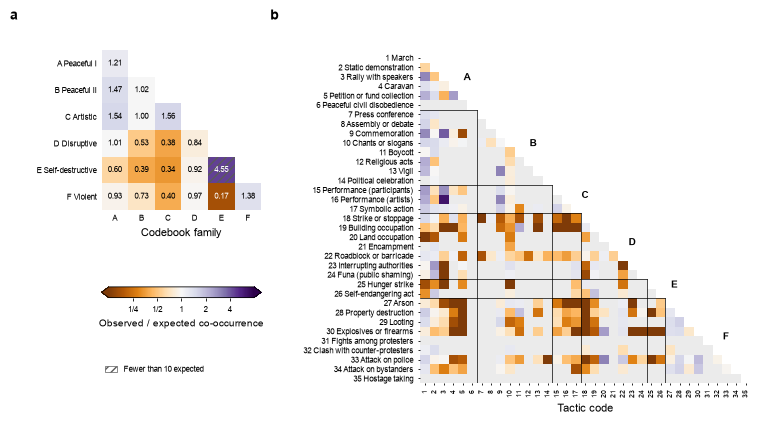

saved Fig2


In [3]:
pairs = pd.read_csv(TAB / "pairs_full_period_N2.csv")
fam = pd.read_csv(TAB / "family_structure.csv"); fam = fam[fam.reference == "N2"]
M = np.full((35, 35), np.nan)
for _, r in pairs.iterrows():
    if r.evaluable:
        M[r.code_j - 1, r.code_i - 1] = r.log2_ratio          # lower triangle
export_source_table(pairs[pairs.evaluable], "fig2b_pair_matrix_N2.csv")
F = pd.DataFrame(np.nan, index=FAM_ORDER, columns=FAM_ORDER); FE = F.copy()
for _, r in fam.iterrows():
    i, j = sorted([FAM_ORDER.index(r.family_a), FAM_ORDER.index(r.family_b)])
    F.iloc[j, i] = r.log2_ratio; FE.iloc[j, i] = r.expected            # lower triangle, diagonal included
export_source_table(fam, "fig2a_family_matrix_N2.csv")

fig = plt.figure(figsize=(7.5, 4.3))
norm = TwoSlopeNorm(vcenter=0, vmin=-3, vmax=3)
ax = fig.add_axes([0.13, 0.5, 0.213, 0.4])
im = ax.imshow(np.clip(F.to_numpy(dtype=float), -3, 3), cmap="PuOr", norm=norm)
for i in range(6):
    for j in range(i + 1):
        v, e = F.iloc[i, j], FE.iloc[i, j]
        if e < 10:
            ax.add_patch(mpl.patches.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, hatch="////", ec="#5A5A5A", lw=0))
        ax.text(j, i, f"{2 ** v:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 1.6 else "black")
ax.set_xticks(range(6), ["A", "B", "C", "D", "E", "F"]); ax.set_yticks(range(6), FAM_ORDER)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0); ax.set_xlabel("Codebook family")
cax = fig.add_axes([0.13, 0.31, 0.213, 0.025])
cb = fig.colorbar(im, cax=cax, orientation="horizontal", extend="both")
cb.set_ticks([-2, -1, 0, 1, 2], labels=["1/4", "1/2", "1", "2", "4"])
cb.set_label("Observed / expected co-occurrence", fontsize=7); cb.ax.tick_params(labelsize=6)
fig.legend(handles=[mpl.patches.Patch(facecolor="white", hatch="////", edgecolor="#5A5A5A", lw=0.5, label="Fewer than 10 expected")],
           loc="upper left", bbox_to_anchor=(0.125, 0.17), fontsize=6, handlelength=1.4, frameon=False)
ax = fig.add_axes([0.555, 0.11, 0.44, 0.77])
grey = np.where(np.tril(np.ones((35, 35)), -1) > 0, 1.0, np.nan); grey[~np.isnan(M)] = np.nan
ax.imshow(grey, cmap=mpl.colors.ListedColormap(["#EBEBEB"]), interpolation="none")
ax.imshow(np.clip(M, -3, 3), cmap="PuOr", norm=norm, interpolation="none")
for b in FAM_BOUNDS:
    ax.plot([-0.5, b - 0.5], [b - 0.5, b - 0.5], color="k", lw=0.5)
    ax.plot([b - 0.5, b - 0.5], [b - 0.5, 34.5], color="k", lw=0.5)
for (lo, hi), letter in zip(zip([1] + [b + 1 for b in FAM_BOUNDS], FAM_BOUNDS + [35]), "ABCDEF"):
    mid = (lo + hi) / 2 - 1
    ax.text(mid + 1.6, mid - 0.4, letter, ha="left", va="center", fontsize=7, fontweight="bold")
ax.set_xticks(range(35), range(1, 36), fontsize=5, rotation=90)
ax.set_yticks(range(35), [f"{c} {short(c)}" for c in range(1, 36)], fontsize=5.5)
ax.tick_params(length=1.5)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel("Tactic code")
fig.text(0.008, 0.95, "a", fontsize=10, fontweight="bold", va="bottom"); fig.text(0.355, 0.95, "b", fontsize=10, fontweight="bold", va="bottom")
save(fig, "Fig2")

## Fig 3 · The same affinities and avoidances recurred every year

,reference,family_a,family_b,year,observed,expected,ratio,lo,hi
0,N2,A Peaceful I,A Peaceful I,2008,137.0,97.715715,1.399980,1.144481,1.638546
1,N2,A Peaceful I,A Peaceful I,2009,103.0,83.470470,1.232576,0.988684,1.475959
2,N2,A Peaceful I,A Peaceful I,2010,87.0,73.749750,1.178455,0.931954,1.413980
3,N2,A Peaceful I,A Peaceful I,2011,150.0,121.606607,1.232530,1.019769,1.451571
4,N2,A Peaceful I,A Peaceful I,2012,130.0,70.127127,1.847732,1.441016,2.284042
...,...,...,...,...,...,...,...,...,...
352,N2,F Violent,F Violent,2020,417.0,320.994994,1.298621,1.131696,1.478999
353,N2,F Violent,F Violent,2021,452.0,357.857858,1.262704,1.124168,1.406077
354,N2,F Violent,F Violent,2022,369.0,243.675675,1.513255,1.333273,1.727484
355,N2,F Violent,F Violent,2023,113.0,72.688689,1.550786,1.215429,1.901891


,reference,year,pairs,pearson,pearson_boot_lo,pearson_boot_hi,reliability_year,reliability_rest,ceiling,disattenuated,disattenuated_boot_lo,disattenuated_boot_hi,detectable_departure
0,N2,2008,61,0.797851,0.635674,0.814481,0.758707,0.973545,0.859439,0.928340,0.778206,1.027722,False
1,N2,2009,51,0.832855,0.623516,0.846006,0.737562,0.968374,0.845125,0.985481,0.775595,1.117212,False
2,N2,2010,32,0.882188,0.716930,0.909924,0.840026,0.977830,0.906313,0.973381,0.829125,1.090862,False
3,N2,2011,84,0.920825,0.782031,0.892699,0.865231,0.956290,0.909622,1.012316,0.904615,1.058575,False
4,N2,2012,62,0.858609,0.726851,0.852653,0.846129,0.970939,0.906388,0.947286,0.834440,1.017478,False
5,N2,2013,66,0.894371,0.685276,0.859708,0.766015,0.956918,0.856162,1.044629,0.869148,1.155735,False
6,N2,2014,60,0.875953,0.691210,0.855117,0.740675,0.974120,0.849415,1.031242,0.867105,1.200193,False
7,N2,2015,32,0.772702,0.569118,0.830746,0.776371,0.982435,0.873346,0.884760,0.696793,1.080245,False
8,N2,2016,66,0.699757,0.501437,0.718955,0.691360,0.958557,0.814069,0.859580,0.648711,1.018304,False
9,N2,2017,41,0.875352,0.549282,0.845828,0.563301,0.975984,0.741467,1.180569,0.712484,1.772716,False


,reference,lag_years,n_year_pairs,mean_pearson,median_pearson,min_pearson,max_pearson
16,N2,1,16,0.770269,0.788374,0.613166,0.870502
17,N2,2,15,0.722002,0.708846,0.467801,0.887261
18,N2,3,14,0.758319,0.770874,0.483832,0.947887
19,N2,4,13,0.705479,0.720156,0.496689,0.873035
20,N2,5,12,0.735455,0.734622,0.578056,0.875644
21,N2,6,11,0.729321,0.739530,0.595422,0.835850
22,N2,7,10,0.759748,0.745962,0.666282,0.841554
23,N2,8,9,0.767252,0.767641,0.659960,0.856340
24,N2,9,8,0.737207,0.727851,0.612749,0.872525
25,N2,10,7,0.699727,0.674411,0.608894,0.843856


Fig3 layout check: ok


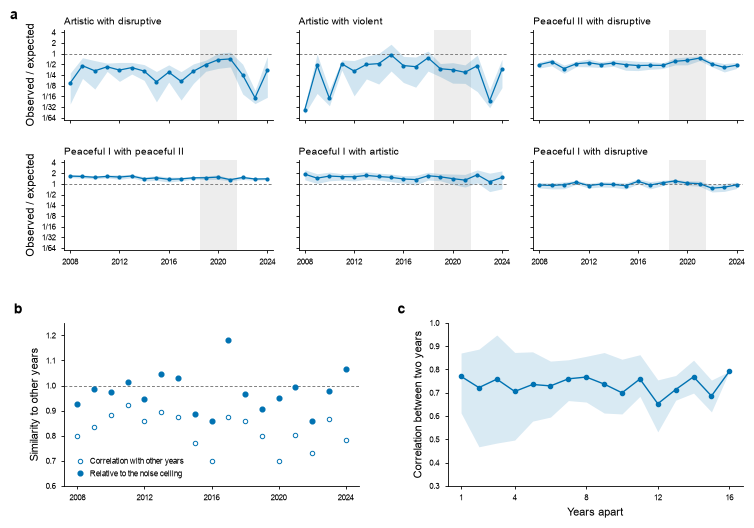

saved Fig3


In [4]:
fy = pd.read_csv(TAB / "family_ratio_by_year.csv"); fy = fy[fy.reference == "N2"]
calib = pd.read_csv(TAB / "annual_calibration.csv"); lagp = pd.read_csv(TAB / "annual_lag_profile.csv")
HEAD = [("C Artistic", "D Disruptive", "Artistic with disruptive"), ("C Artistic", "F Violent", "Artistic with violent"),
        ("B Peaceful II", "D Disruptive", "Peaceful II with disruptive"), ("A Peaceful I", "B Peaceful II", "Peaceful I with peaceful II"),
        ("A Peaceful I", "C Artistic", "Peaceful I with artistic"), ("A Peaceful I", "D Disruptive", "Peaceful I with disruptive")]
export_source_table(fy, "fig3a_family_ratio_by_year_N2.csv")
fig = plt.figure(figsize=(7.5, 5.3))
outer = GridSpec(2, 1, figure=fig, height_ratios=[1.35, 1], hspace=0.38, left=0.08, right=0.985, top=0.95, bottom=0.09)
top = outer[0].subgridspec(2, 3, wspace=0.12, hspace=0.45)
sel = pd.concat([fy[(fy.family_a == fa) & (fy.family_b == fb)] for fa, fb, _ in HEAD])
ylo, yhi = max(np.floor(np.log2(sel.lo).min()) - 0.2, -6.2), np.ceil(np.log2(sel.hi).max()) + 0.2
for k, (fa, fb, name) in enumerate(HEAD):
    ax = fig.add_subplot(top[k // 3, k % 3]); z = fy[(fy.family_a == fa) & (fy.family_b == fb)].sort_values("year")
    ax.axvspan(2018.5, 2021.5, color="#EDEDED", lw=0, zorder=0); ax.axhline(0, color="#7F7F7F", lw=0.7, ls=(0, (3, 2)))
    ax.fill_between(z.year, np.log2(z.lo).clip(ylo), np.log2(z.hi), color=REF_COLOR["N2"], alpha=0.18, lw=0)
    ax.plot(z.year, np.log2(z.ratio), "-o", color=REF_COLOR["N2"], ms=2, lw=0.9)
    ax.set_ylim(ylo, yhi); fold_axis(ax.yaxis, ylo, yhi); ax.set_xlim(2007.5, 2024.5); ax.set_xticks([2008, 2012, 2016, 2020, 2024])
    ax.text(0, 1.04, name, transform=ax.transAxes, fontsize=7, ha="left", va="bottom")
    if k % 3:
        ax.tick_params(labelleft=False)
    else:
        ax.set_ylabel("Observed / expected")
    if k < 3:
        ax.tick_params(labelbottom=False)
fig.text(0.008, 0.965, "a", fontsize=10, fontweight="bold", va="bottom")
bot = outer[1].subgridspec(1, 2, wspace=0.3)
ax = fig.add_subplot(bot[0, 0]); c = calib[calib.reference == "N2"]
ax.axhline(1, color="#7F7F7F", lw=0.7, ls=(0, (3, 2)))
ax.plot(c.year, c.pearson, "o", mfc="white", mec=REF_COLOR["N2"], ms=3.2, mew=0.7, label="Correlation with other years")
ax.plot(c.year, c.disattenuated, "o", color=REF_COLOR["N2"], ms=3.4, label="Relative to the noise ceiling")
ax.set_ylim(0.6, 1.25); ax.set_xticks(YEARS[::4]); ax.set_ylabel("Similarity to other years")
ax.legend(loc="lower left", fontsize=6, handletextpad=0.2)
panel_letter(ax, "b", x=-0.17, y=1.04)
ax = fig.add_subplot(bot[0, 1]); z = lagp[lagp.reference == "N2"]
ax.fill_between(z.lag_years, z.min_pearson, z.max_pearson, color=REF_COLOR["N2"], alpha=0.15, lw=0)
ax.plot(z.lag_years, z.mean_pearson, "-o", color=REF_COLOR["N2"], ms=3, lw=1)
ax.set_xticks([1, 4, 8, 12, 16]); ax.set_ylim(0.3, 1.0); ax.set_xlabel("Years apart"); ax.set_ylabel("Correlation between two years")
panel_letter(ax, "c", x=-0.17, y=1.04)
export_source_table(c, "fig3b_similarity_N2.csv"); export_source_table(z, "fig3c_lag_profile_N2.csv")
save(fig, "Fig3")

## Fig 4 · Where the pattern bent: departures by year and the pairs behind them (N2)

,reference,year,cells,pairs_new_vs_other_years,X2_between,df_between,X2_within_mean,df_within_mean,dispersion_within,F,p_F,share_beyond_noise,p_holm
0,N2,2008,99,2,179.733667,98,127.408707,88.0,1.447826,1.266738,1.296678e-01,0.210571,1.000000e+00
1,N2,2009,94,0,130.835277,93,100.353072,85.0,1.180624,1.191599,2.064129e-01,0.160792,1.000000e+00
2,N2,2010,72,0,64.284242,71,66.779345,60.0,1.112989,0.813496,7.989197e-01,0.000000,1.000000e+00
3,N2,2011,139,0,197.554612,138,138.977769,121.0,1.148577,1.246373,1.075024e-01,0.197672,9.675219e-01
4,N2,2012,111,1,209.211008,110,106.396077,94.0,1.131873,1.680328,5.090661e-03,0.404878,6.617859e-02
5,N2,2013,118,0,155.773956,117,121.950019,103.0,1.183981,1.124513,2.716767e-01,0.110726,1.000000e+00
6,N2,2014,101,0,149.414365,100,107.728786,86.0,1.252660,1.192776,2.011024e-01,0.161620,1.000000e+00
7,N2,2015,77,0,125.242136,76,77.553565,67.0,1.157516,1.423672,7.063572e-02,0.297591,7.769929e-01
8,N2,2016,117,1,267.919889,116,134.122552,101.0,1.327946,1.739268,2.335013e-03,0.425046,3.269018e-02
9,N2,2017,84,0,93.385937,83,91.907693,74.0,1.241996,0.905906,6.701442e-01,0.000000,1.000000e+00


,year,direction,code_i,code_j,label_i,label_j,observed,predicted_common_structure,ratio,pearson_residual
16,2019,more_than_common_structure,11,27,Boycott,Arson,20,0.811912,24.633213,21.294980
17,2019,more_than_common_structure,2,33,Static demonstration,Attack on police or security forces,124,70.460011,1.759863,6.378329
18,2019,more_than_common_structure,2,34,Static demonstration,Attack on bystanders,8,1.528856,5.232669,5.233566
19,2019,more_than_common_structure,15,22,Artistic performance (participants),Roadblock or barricade,14,4.140617,3.381138,4.845261
20,2019,more_than_common_structure,2,27,Static demonstration,Arson,42,21.205411,1.980627,4.515720
21,2019,more_than_common_structure,2,28,Static demonstration,Property destruction,97,63.542612,1.526535,4.197198
22,2019,more_than_common_structure,15,27,Artistic performance (participants),Arson,3,0.453561,6.614327,3.781077
23,2019,more_than_common_structure,2,16,Static demonstration,Artistic performance (artists),13,5.012225,2.593659,3.567883
24,2019,fewer_than_common_structure,18,22,Strike or stoppage,Roadblock or barricade,16,55.679646,0.287358,-5.317648
25,2019,fewer_than_common_structure,1,28,March,Property destruction,96,140.865998,0.681499,-3.780195


Fig4 layout check: ok


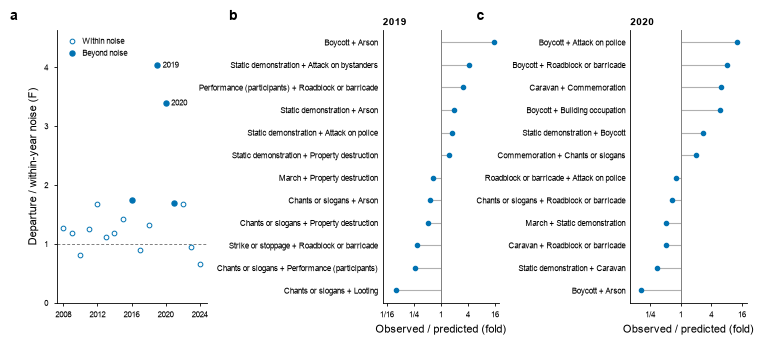

saved Fig4


In [5]:
Ftab = pd.read_csv(TAB / "annual_departure_F.csv"); Fn2 = Ftab[Ftab.reference == "N2"]
dep = pd.read_csv(TAB / "departure_pairs_flagged_years_N2.csv")
export_source_table(Fn2, "fig4a_departure_F_N2.csv"); export_source_table(dep[dep.year.isin([2019, 2020])], "fig4bc_departure_pairs_N2.csv")
fig = plt.figure(figsize=(7.5, 3.5))
ax = fig.add_axes([0.07, 0.14, 0.2, 0.78])
flag = Fn2.p_holm < 0.05
ax.axhline(1, color="#7F7F7F", lw=0.7, ls=(0, (3, 2)))
ax.plot(Fn2.year[~flag], Fn2.F[~flag], "o", mfc="white", mec=REF_COLOR["N2"], ms=3.4, mew=0.7, label="Within noise")
ax.plot(Fn2.year[flag], Fn2.F[flag], "o", color=REF_COLOR["N2"], ms=3.6, label="Beyond noise")
for yr in (2019, 2020):
    v = Fn2.set_index("year").F[yr]
    ax.annotate(str(yr), (yr, v), xytext=(4, 0), textcoords="offset points", fontsize=6, va="center")
ax.set_ylim(0, Fn2.F.max() * 1.15); ax.set_xticks(YEARS[::4]); ax.set_ylabel("Departure / within-year noise (F)")
ax.legend(loc="upper left", fontsize=6, handletextpad=0.2)
fig.text(0.008, 0.94, "a", fontsize=10, fontweight="bold", va="bottom")
for k, (yr, x0) in enumerate(((2019, 0.505), (2020, 0.835))):
    ax = fig.add_axes([x0, 0.14, 0.155, 0.78]); d = dep[dep.year == yr]
    d = pd.concat([d[d.direction.str.startswith("more")].nlargest(6, "pearson_residual"),
                   d[d.direction.str.startswith("fewer")].nsmallest(6, "pearson_residual")]).copy()
    d["lr"] = np.log2((d.observed + 0.5) / (d.predicted_common_structure + 0.5)); d = d.sort_values("lr")
    yy = np.arange(len(d))
    ax.hlines(yy, 0, d.lr, color="#B0B0B0", lw=0.8)
    ax.plot(d.lr, yy, "o", color=REF_COLOR["N2"], ms=3)
    ax.axvline(0, color="#7F7F7F", lw=0.7)
    ax.set_yticks(yy, [f"{short(i)} + {short(j)}" for i, j in zip(d.code_i, d.code_j)], fontsize=6); ax.tick_params(axis="y", length=0)
    lo_, hi_ = np.floor(d.lr.min()) - 0.3, np.ceil(d.lr.max()) + 0.3
    ax.set_xlim(lo_, hi_); fold_axis(ax.xaxis, lo_, hi_, step=2 if hi_ - lo_ > 6 else 1)
    ax.set_xlabel("Observed / predicted (fold)")
    ax.text(0.0, 1.01, str(yr), transform=ax.transAxes, fontsize=7, fontweight="bold", ha="left", va="bottom")
    fig.text(x0 - 0.205, 0.94, "bc"[k], fontsize=10, fontweight="bold", va="bottom")
save(fig, "Fig4")

## Supplementary figures, in order of citation

,1,2,3,4,5,7,8,9,10,11,...,24,25,26,27,28,29,30,32,33,34
2008,-0.225454,-0.119853,0.045319,-0.659244,0.383435,-1.473436,0.642042,-0.576547,-0.527441,-5.223389,...,-0.986569,0.783832,-0.000119,-2.689351,-0.316739,-2.372520,-1.079374,-0.730014,-0.167614,-0.535590
2009,-0.072929,-0.201967,0.653082,-0.566405,0.303883,-2.623458,-2.623458,0.740059,-0.358408,-4.733613,...,0.156923,1.051930,1.354982,-1.844495,-0.590320,-4.196323,-0.577188,-1.112137,-0.436040,-1.343502
2010,0.165589,0.206060,0.693829,-2.021783,0.289845,-2.375990,1.083441,0.074244,0.204433,-4.445393,...,-0.691099,1.822542,0.769728,-1.823695,-1.690686,-5.486618,-1.054296,-1.578979,-0.781257,-1.051525
2011,0.341201,-0.451678,0.498349,-0.124833,0.186125,-1.612091,-0.389699,-1.036400,-0.281028,-5.375990,...,0.657930,0.445120,0.416711,-1.798112,-0.084355,-1.790221,-1.352080,-1.724615,0.317834,-1.650925
2012,0.164849,-0.493114,0.822568,-0.868795,0.346713,-2.663771,0.795660,-0.320281,-0.852824,-1.972477,...,0.899021,-0.286452,0.866749,-0.525476,-0.186080,-1.436104,0.163724,-0.670330,0.380022,-0.542258
2013,0.105533,-0.439849,0.002531,-1.009172,0.366287,0.231691,-0.616306,-0.690079,-0.369257,-1.182991,...,0.181279,-0.327551,0.228496,-1.010917,-0.433539,-2.973979,-0.389507,-1.450272,-0.245265,-0.400914
2014,0.200239,-0.625817,0.344023,0.230408,-0.031209,0.994217,0.257252,-1.103510,-0.470505,-1.891394,...,0.511587,-0.070523,-0.449461,-0.738893,-0.995024,-4.529927,-0.082419,-2.159977,-0.620862,-0.372087
2015,0.317066,-0.211063,-0.485107,-0.857318,-1.116548,0.974425,0.684918,-1.983248,-0.728238,-2.251441,...,0.317837,0.018100,-0.514134,-0.093518,-2.344173,-2.810265,-0.528889,1.360393,-1.061732,-0.333267
2016,0.374648,0.204660,-0.033810,0.440544,-1.536694,2.666379,0.410039,-2.513045,-0.234966,-0.496971,...,0.978639,0.237075,0.227911,0.211782,-0.889744,-2.480502,-1.026793,-0.411368,-0.728011,0.084051
2017,0.177633,-0.082980,-0.022033,0.496304,0.632246,-0.713131,-0.713131,-1.019522,0.314654,-2.767912,...,0.624273,0.041610,0.526537,-0.226482,-0.756257,-2.584380,-0.958248,0.381447,-0.961811,-0.006540


,actions,multi_tactic,mean_k
year,,,
2008,2015,798,1.570720
2009,1419,603,1.589852
2010,1152,535,1.601562
2011,2246,982,1.671861
2012,1467,639,1.610089
2013,1832,844,1.644105
2014,1795,746,1.551532
2015,1264,435,1.477057
2016,1587,847,1.747322


S1_Fig layout check: ok


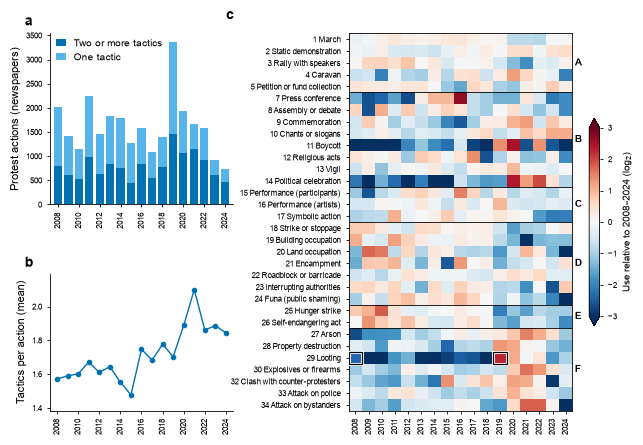

saved S1_Fig


In [6]:
# S1 Fig: annual volume, list length and tactic frequencies
cov = pd.read_csv(TAB / "annual_coverage.csv"); cov = cov[cov["sample"] == "newspapers"].set_index("year")
marg = pd.read_csv(TAB / "tactic_counts_by_year.csv").set_index("year"); marg.columns = marg.columns.astype(int)
tot = marg.sum(); keep = [c for c in range(1, 36) if tot[c] >= 50]
expected = np.outer(cov.actions, tot[keep] / cov.actions.sum())
rel = np.log2((marg[keep].to_numpy() + 0.5) / (expected + 0.5))         # years x tactics
fig1_data = pd.DataFrame(rel, index=YEARS, columns=keep)
export_source_table(fig1_data, "S1_relative_frequency.csv", index=True)
export_source_table(cov[["actions", "multi_tactic", "mean_k"]], "S1_volume.csv", index=True)

fig = plt.figure(figsize=(7.5, 4.9))
gs = GridSpec(2, 2, figure=fig, width_ratios=[1, 1.55], height_ratios=[1.25, 1], wspace=0.5, hspace=0.45)
ax = fig.add_subplot(gs[0, 0])
single = cov.actions - cov.multi_tactic
ax.bar(YEARS, cov.multi_tactic, color=OI["blue"], width=0.8, label="Two or more tactics")
ax.bar(YEARS, single, bottom=cov.multi_tactic, color=OI["sky"], width=0.8, label="One tactic")
ax.set_ylabel("Protest actions (newspapers)"); ax.set_xticks(YEARS[::2]); ax.tick_params(axis="x", rotation=90)
ax.legend(loc="upper left", handlelength=1, borderaxespad=0.2); ax.margins(x=0.02)
panel_letter(ax, "a")
ax = fig.add_subplot(gs[1, 0])
ax.plot(YEARS, cov.mean_k, "o-", color=OI["blue"], ms=3, lw=1)
ax.set_ylabel("Tactics per action (mean)"); ax.set_xticks(YEARS[::2]); ax.tick_params(axis="x", rotation=90)
ax.margins(x=0.04, y=0.15)
panel_letter(ax, "b")
ax = fig.add_subplot(gs[:, 1])
norm = TwoSlopeNorm(vcenter=0, vmin=-3, vmax=3)
im = ax.imshow(np.clip(rel.T, -3, 3), aspect="auto", cmap="RdBu_r", norm=norm, interpolation="none")
ax.set_xticks(range(len(YEARS)), YEARS, rotation=90); ax.set_yticks(range(len(keep)), [f"{c} {short(c)}" for c in keep])
fam_of = [dic.loc[c, "family_label"] for c in keep]
for i in range(1, len(keep)):
    if fam_of[i] != fam_of[i - 1]:
        ax.axhline(i - 0.5, color="k", lw=0.6)
for fam in FAM_ORDER:
    idx = [i for i, f in enumerate(fam_of) if f == fam]
    if idx:
        ax.text(len(YEARS) - 0.3, np.mean(idx), fam.split(" ", 1)[0], va="center", ha="left", fontsize=7, fontweight="bold")
i29 = keep.index(29)                                                   # looting: the example opening the abstract
for yr in (2008, 2019):
    for lw, col in ((2.2, "white"), (0.9, "black")):
        ax.add_patch(mpl.patches.Rectangle((yr - YEARS[0] - 0.5, i29 - 0.5), 1, 1, fill=False, ec=col, lw=lw, zorder=3))
ax.spines[["top", "right"]].set_visible(True)
cb = fig.colorbar(im, ax=ax, shrink=0.55, pad=0.06, extend="both")
cb.set_label("Use relative to 2008–2024 (log$_2$)", fontsize=7); cb.ax.tick_params(labelsize=6)
panel_letter(ax, "c", x=-0.55)
save(fig, "S1_Fig")

,spec,actions,multi_tactic_actions,occupied_fields,strata,fields_in_fixed_strata,observed_pairs_total,seconds,pairs_with_variable_reference,rhat_median,rhat_p99,rhat_max,pairs_rhat_gt_1.05,lag1_median,lag1_p90_abs,ess_median_top60,ess_min_top60,acceptance_mean,changed_fields_mean
0,N1,27488,13405,47097,204,0.000000,28256,33.0,591,0.999634,1.007904,1.013231,0,-0.005637,0.101972,996.0,874.896043,0.620255,0.871467
1,N2,27488,13405,47097,1536,0.008960,28256,32.0,584,0.999656,1.006818,1.011511,0,-0.005713,0.104684,996.0,799.737843,0.584209,0.738566
2,N2_clean,23559,6666,32707,1362,0.011802,12310,20.4,516,0.999558,1.006276,1.009244,0,-0.003857,0.105635,996.0,865.388920,0.614812,0.730035
3,N2_allmedia,34118,15863,56964,1575,0.007040,32443,38.0,587,0.999702,1.006972,1.007844,0,-0.005122,0.100420,996.0,996.000000,0.597585,0.747832
4,N2_order,27488,13405,47097,1536,0.008960,28256,41.5,584,0.999719,1.006301,1.013209,0,-0.000683,0.102160,996.0,886.190418,0.382012,0.686546
5,N1_k2,8981,8981,17962,204,0.000000,8981,11.7,560,0.999739,1.006689,1.007306,0,-0.009639,0.097969,996.0,899.603331,0.554476,0.836808


S2_Fig layout check: ok


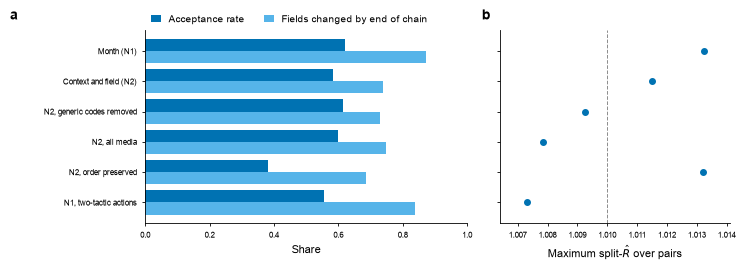

saved S2_Fig


In [7]:
# S2 Fig: sampler validation
mcmc = pd.read_csv(TAB / "mcmc_diagnostics.csv")
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.8), sharey=True, gridspec_kw={"wspace": 0.12, "width_ratios": [1.4, 1]})
fig.subplots_adjust(left=0.2, right=0.98, bottom=0.17, top=0.86)
y = np.arange(len(mcmc))[::-1]
ax = axes[0]
ax.barh(y + 0.2, mcmc.acceptance_mean, 0.4, color=OI["blue"], label="Acceptance rate")
ax.barh(y - 0.2, mcmc.changed_fields_mean, 0.4, color=OI["sky"], label="Fields changed by end of chain")
ax.set_yticks(y, [REF_LABEL[s] for s in mcmc.spec]); ax.set_xlabel("Share"); ax.set_xlim(0, 1)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, handlelength=1, borderaxespad=0.2); panel_letter(ax, "a", x=-0.42, y=1.04)
ax = axes[1]
ax.plot(mcmc.rhat_max, y, "o", color=OI["blue"], ms=4)
ax.axvline(1.01, color=OI["grey"], lw=0.7, ls="--")
ax.set_xlabel("Maximum split-$\\hat{R}$ over pairs"); ax.margins(x=0.15)
panel_letter(ax, "b", x=-0.08, y=1.04)
export_source_table(mcmc, "S2_mcmc.csv")
save(fig, "S2_Fig")

,reference,code_i,code_j,label_i,label_j,observed_2008_2018,observed_2021_2024,expected_2008_2018,expected_2021_2024,share_change_observed,share_change_expected,association_change,lo,hi,beyond_noise
108,N1,1,2,March,Static demonstration,226.0,57.0,666.582583,192.154154,-0.819088,-0.633063,-0.186025,-0.666117,0.245065,False
109,N1,1,3,March,Rally with speakers,390.0,49.0,114.863864,12.228228,-1.821033,-2.021299,0.200266,-0.487181,0.684640,False
110,N1,1,4,March,Caravan,41.0,13.0,48.454454,11.173173,-0.461363,-0.909454,0.448091,-0.617242,1.321794,False
111,N1,1,5,March,Petition or fund collection,218.0,60.0,93.917918,20.742743,-0.693837,-0.993301,0.299464,-0.146406,0.731784,False
112,N1,1,9,March,Commemoration,81.0,83.0,49.144144,32.028028,1.193765,0.548849,0.644916,-0.162875,1.203660,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
216,N1,27,34,Arson,Attack on bystanders,57.0,95.0,6.323323,24.358358,1.890728,3.023974,-1.133246,-1.626273,-0.642590,True
217,N1,28,30,Property destruction,Explosives or firearms,79.0,47.0,12.216216,17.429429,0.415762,1.654449,-1.238687,-1.802668,-0.681903,True
218,N1,28,33,Property destruction,Attack on police or security forces,200.0,84.0,32.451451,16.759760,-0.087790,0.225860,-0.313649,-0.668123,0.010682,False
219,N1,30,33,Explosives or firearms,Attack on police or security forces,241.0,157.0,25.901902,38.980981,0.542118,1.739305,-1.197187,-1.575660,-0.831106,True


,reference,year,pairs,r_expected_observed,reduction_vs_unchanged_share,median_abs_share_change,median_abs_association_change
0,N2,2008,61,0.826667,0.666659,0.624463,0.366147
1,N2,2009,51,0.804263,0.676710,0.845139,0.348606
2,N2,2010,32,0.649789,0.369406,0.747021,0.354302
3,N2,2011,84,0.853140,0.750951,0.786919,0.333299
4,N2,2012,62,0.682998,0.479959,0.683761,0.405724
5,N2,2013,66,0.815726,0.698023,0.636241,0.272741
6,N2,2014,60,0.791488,0.652453,0.564532,0.323425
7,N2,2015,32,0.502350,0.339040,0.481757,0.338824
8,N2,2016,66,0.785361,0.647855,0.797105,0.366731
9,N2,2017,41,0.783582,0.661915,0.517423,0.353997


S3_Fig layout check: ok


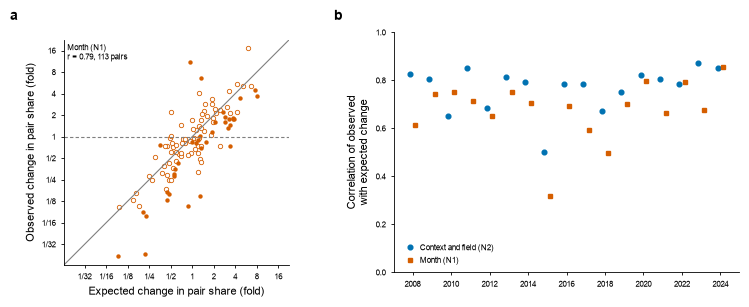

saved S3_Fig


In [8]:
# S3 Fig: change in pair shares under the monthly reference (N1) and year by year
cby = pd.read_csv(TAB / "change_by_year.csv")
cpair_all = pd.read_csv(TAB / "change_pairs_blocks.csv"); csum = pd.read_csv(TAB / "change_summary.csv").set_index("reference")
c1 = cpair_all[cpair_all.reference == "N1"]
fig = plt.figure(figsize=(7.5, 3.2))
ax = fig.add_axes([0.08, 0.15, 0.3, 0.75])
x, y, beyond = c1.share_change_expected.to_numpy(), c1.share_change_observed.to_numpy(), c1.beyond_noise.to_numpy()
lo_c, hi_c = min(x.min(), y.min()) - 0.4, max(x.max(), y.max()) + 0.4
ax.plot([lo_c, hi_c], [lo_c, hi_c], color="#7F7F7F", lw=0.8); ax.axhline(0, color="#7F7F7F", lw=0.8, ls=(0, (3, 2)))
ax.scatter(x[~beyond], y[~beyond], s=10, facecolor="white", edgecolor=REF_COLOR["N1"], lw=0.6)
ax.scatter(x[beyond], y[beyond], s=10, color=REF_COLOR["N1"], lw=0)
s1 = csum.loc["N1"]
ax.text(lo_c + 0.15, hi_c - 0.15, f"{REF_LABEL['N1']}\nr = {s1.r_expected_observed:.2f}, {int(s1.pairs)} pairs", ha="left", va="top", fontsize=6)
ax.set_xlim(lo_c, hi_c); ax.set_ylim(lo_c, hi_c); ax.set_aspect("equal"); fold_axis(ax.xaxis, lo_c, hi_c); fold_axis(ax.yaxis, lo_c, hi_c)
ax.set_xlabel("Expected change in pair share (fold)"); ax.set_ylabel("Observed change in pair share (fold)")
fig.text(0.008, 0.93, "a", fontsize=10, fontweight="bold", va="bottom")
ax = fig.add_axes([0.52, 0.15, 0.46, 0.75])
for name, mk, off in [("N2", "o", -0.15), ("N1", "s", 0.15)]:
    z = cby[cby.reference == name]
    ax.plot(z.year + off, z.r_expected_observed, mk, color=REF_COLOR[name], ms=3.4, label=REF_LABEL[name])
ax.set_ylim(0, 1); ax.set_xticks(YEARS[::2]); ax.set_ylabel("Correlation of observed\nwith expected change")
ax.legend(loc="lower left", fontsize=6, handletextpad=0.2)
fig.text(0.44, 0.93, "b", fontsize=10, fontweight="bold", va="bottom")
export_source_table(c1, "S3_pair_changes_N1.csv"); export_source_table(cby, "S3_change_by_year.csv")
save(fig, "S3_Fig")

,code_i,code_j,label_i,label_j,family_i,family_j,observed,expected,sd_reference,difference,z,log2_ratio,p_mc_two_sided,q_bh_595,eligible_primary,evaluable
0,1,2,March,Static demonstration,A Peaceful I,A Peaceful I,358,1085.877878,25.687405,-727.877878,-28.335983,-1.599481,0.002,0.006166,True,True
1,1,3,March,Rally with speakers,A Peaceful I,A Peaceful I,482,142.777778,10.325595,339.222222,32.852561,1.751714,0.002,0.006166,True,True
2,1,4,March,Caravan,A Peaceful I,A Peaceful I,77,85.723724,8.091891,-8.723724,-1.078082,-0.153889,0.318,0.551633,True,True
3,1,5,March,Petition or fund collection,A Peaceful I,A Peaceful I,312,126.759760,9.887156,185.240240,18.735442,1.296080,0.002,0.006166,True,True
5,1,7,March,Press conference or statement,A Peaceful I,B Peaceful II,13,8.940941,2.667160,4.059059,1.521866,0.515957,0.182,0.352736,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
578,29,34,Looting,Attack on bystanders,F Violent,F Violent,11,5.250250,2.166292,5.749750,2.654189,0.999937,0.030,0.073457,True,True
582,30,33,Explosives or firearms,Attack on police or security forces,F Violent,F Violent,519,92.280280,8.746343,426.719720,48.788358,2.485234,0.002,0.006166,True,True
583,30,34,Explosives or firearms,Attack on bystanders,F Violent,F Violent,171,23.523524,4.280402,147.476476,34.453885,2.835689,0.002,0.006166,True,True
589,32,33,Clashes with counter-protesters,Attack on police or security forces,F Violent,F Violent,20,8.314314,2.682480,11.685686,4.356300,1.217704,0.002,0.006166,True,True


S4_Fig layout check: ok


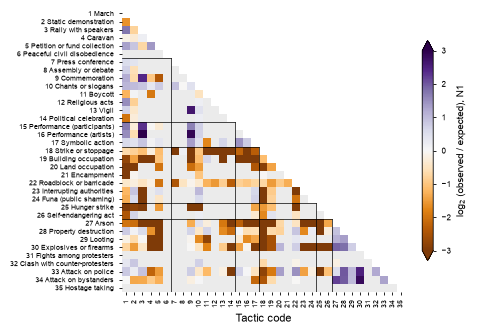

saved S4_Fig


In [9]:
# S4 Fig: pair matrix under N1
pairs1 = pd.read_csv(TAB / "pairs_full_period_N1.csv")
M1 = np.full((35, 35), np.nan)
for _, r in pairs1.iterrows():
    if r.evaluable:
        M1[r.code_j - 1, r.code_i - 1] = r.log2_ratio
fig, ax = plt.subplots(figsize=(5.6, 4.6))
fig.subplots_adjust(left=0.27, right=0.9, bottom=0.1, top=0.97)
grey = np.where(np.tril(np.ones((35, 35)), -1) > 0, 1.0, np.nan); grey[~np.isnan(M1)] = np.nan
ax.imshow(grey, cmap=mpl.colors.ListedColormap(["#EBEBEB"]), interpolation="none")
im = ax.imshow(np.clip(M1, -3, 3), cmap="PuOr", norm=TwoSlopeNorm(vcenter=0, vmin=-3, vmax=3), interpolation="none")
for b in FAM_BOUNDS:
    ax.plot([-0.5, b - 0.5], [b - 0.5, b - 0.5], color="k", lw=0.5); ax.plot([b - 0.5, b - 0.5], [b - 0.5, 34.5], color="k", lw=0.5)
ax.set_xticks(range(35), range(1, 36), fontsize=5, rotation=90); ax.set_yticks(range(35), [f"{c} {short(c)}" for c in range(1, 36)], fontsize=5)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel("Tactic code")
cb = fig.colorbar(im, ax=ax, shrink=0.55, extend="both"); cb.set_label("log$_2$ (observed / expected), N1", fontsize=7)
export_source_table(pairs1[pairs1.evaluable], "S4_pair_matrix_N1.csv")
save(fig, "S4_Fig")

,year,code_i,code_j,rest,year_value
0,2008,1,2,-0.743737,-0.859518
1,2008,1,3,1.550194,1.866232
2,2008,1,5,1.110513,1.399501
3,2008,1,10,0.635609,0.779954
4,2008,1,17,0.755193,1.374984
...,...,...,...,...,...
1052,2024,18,22,-0.107365,0.520198
1053,2024,22,28,0.361030,0.021729
1054,2024,22,30,0.372337,0.138322
1055,2024,22,33,0.807996,1.026442


S5_Fig layout check: ok


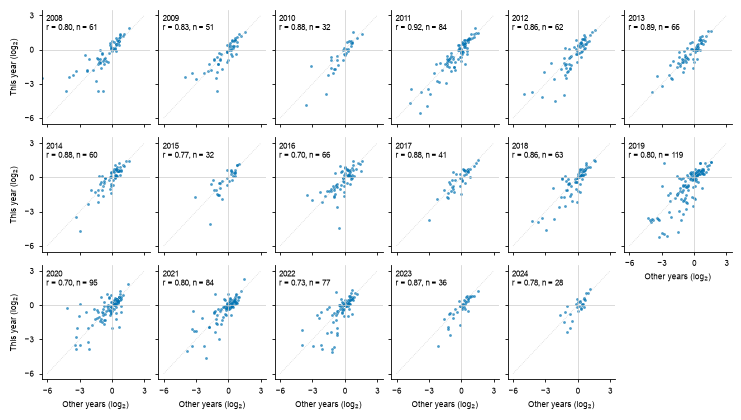

saved S5_Fig


In [10]:
# S5 Fig: every year against the other years (N2), one panel per year
z = np.load(AGG / "null_N2.npz"); Oy = z["observed_year"].astype(float); C = z["counts"].astype(float); Ey = C.mean(0); sdy = C.std(0, ddof=1)
elig = np.load(AGG / "eligible_primary.npy"); lr = lambda O, E: np.log2((O + .5) / (E + .5))
fig, axes = plt.subplots(3, 6, figsize=(7.5, 4.2), sharex=True, sharey=True, gridspec_kw={"wspace": 0.08, "hspace": 0.12})
rows = []
for ti, (yr, ax) in enumerate(zip(YEARS, axes.ravel())):
    Or, Er = Oy.sum(0) - Oy[ti], Ey.sum(0) - Ey[ti]; sdr = (C.sum(1) - C[:, ti, :]).std(0, ddof=1)
    m = elig & (Ey[ti] >= 5) & (Er >= 5) & (sdy[ti] > 0) & (sdr > 0)
    a, b = lr(Or, Er)[m], lr(Oy[ti], Ey[ti])[m]
    ax.axhline(0, color="#CCCCCC", lw=0.5); ax.axvline(0, color="#CCCCCC", lw=0.5)
    ax.plot([-6, 3], [-6, 3], color="#CCCCCC", lw=0.5, ls=":")
    ax.scatter(a, b, s=4, color=OI["blue"], alpha=0.7, lw=0)
    ax.text(0.04, 0.96, f"{yr}\nr = {np.corrcoef(a, b)[0, 1]:.2f}, n = {m.sum()}", transform=ax.transAxes, va="top", fontsize=6)
    rows += [{"year": yr, "code_i": PAIRS[h, 0], "code_j": PAIRS[h, 1], "rest": lr(Or, Er)[h], "year_value": lr(Oy[ti], Ey[ti])[h]} for h in np.where(m)[0]]
axes.ravel()[-1].axis("off"); axes[1, -1].xaxis.set_tick_params(labelbottom=True)
fig.subplots_adjust(left=0.07, right=0.99, bottom=0.1, top=0.98)
for ax in list(axes[-1, :-1]) + [axes[1, -1]]:
    ax.set_xlabel("Other years (log$_2$)", fontsize=6)
for ax in axes[:, 0]:
    ax.set_ylabel("This year (log$_2$)", fontsize=6)
ax.set_xlim(-6.5, 3.5); ax.set_ylim(-6.5, 3.5); ax.set_xticks([-6, -3, 0, 3]); ax.set_yticks([-6, -3, 0, 3])
export_source_table(pd.DataFrame(rows), "S5_year_vs_rest_scatter_N2.csv")
save(fig, "S5_Fig")

,reference,year,pairs,pearson,pearson_boot_lo,pearson_boot_hi,reliability_year,reliability_rest,ceiling,disattenuated,disattenuated_boot_lo,disattenuated_boot_hi,detectable_departure
0,N2,2008,61,0.797851,0.635674,0.814481,0.758707,0.973545,0.859439,0.928340,0.778206,1.027722,False
1,N2,2009,51,0.832855,0.623516,0.846006,0.737562,0.968374,0.845125,0.985481,0.775595,1.117212,False
2,N2,2010,32,0.882188,0.716930,0.909924,0.840026,0.977830,0.906313,0.973381,0.829125,1.090862,False
3,N2,2011,84,0.920825,0.782031,0.892699,0.865231,0.956290,0.909622,1.012316,0.904615,1.058575,False
4,N2,2012,62,0.858609,0.726851,0.852653,0.846129,0.970939,0.906388,0.947286,0.834440,1.017478,False
5,N2,2013,66,0.894371,0.685276,0.859708,0.766015,0.956918,0.856162,1.044629,0.869148,1.155735,False
6,N2,2014,60,0.875953,0.691210,0.855117,0.740675,0.974120,0.849415,1.031242,0.867105,1.200193,False
7,N2,2015,32,0.772702,0.569118,0.830746,0.776371,0.982435,0.873346,0.884760,0.696793,1.080245,False
8,N2,2016,66,0.699757,0.501437,0.718955,0.691360,0.958557,0.814069,0.859580,0.648711,1.018304,False
9,N2,2017,41,0.875352,0.549282,0.845828,0.563301,0.975984,0.741467,1.180569,0.712484,1.772716,False


,reference,lag_years,n_year_pairs,mean_pearson,median_pearson,min_pearson,max_pearson
0,N1,1,16,0.811159,0.813875,0.716472,0.894180
1,N1,2,15,0.796698,0.820308,0.579148,0.886940
2,N1,3,14,0.800034,0.818506,0.562377,0.876279
3,N1,4,13,0.751169,0.759784,0.637823,0.864216
4,N1,5,12,0.754278,0.768350,0.578651,0.872872
...,...,...,...,...,...,...,...
91,N1_k2,12,5,0.838198,0.838960,0.789456,0.870583
92,N1_k2,13,4,0.793008,0.803761,0.634945,0.929567
93,N1_k2,14,3,0.840427,0.839990,0.802163,0.879128
94,N1_k2,15,2,0.707617,0.707617,0.705082,0.710153


,reference,year,cells,pairs_new_vs_other_years,X2_between,df_between,X2_within_mean,df_within_mean,dispersion_within,F,p_F,share_beyond_noise,p_holm
0,N2,2008,99,2,179.733667,98,127.408707,88.0,1.447826,1.266738,1.296678e-01,0.210571,1.000000e+00
1,N2,2009,94,0,130.835277,93,100.353072,85.0,1.180624,1.191599,2.064129e-01,0.160792,1.000000e+00
2,N2,2010,72,0,64.284242,71,66.779345,60.0,1.112989,0.813496,7.989197e-01,0.000000,1.000000e+00
3,N2,2011,139,0,197.554612,138,138.977769,121.0,1.148577,1.246373,1.075024e-01,0.197672,9.675219e-01
4,N2,2012,111,1,209.211008,110,106.396077,94.0,1.131873,1.680328,5.090661e-03,0.404878,6.617859e-02
5,N2,2013,118,0,155.773956,117,121.950019,103.0,1.183981,1.124513,2.716767e-01,0.110726,1.000000e+00
6,N2,2014,101,0,149.414365,100,107.728786,86.0,1.252660,1.192776,2.011024e-01,0.161620,1.000000e+00
7,N2,2015,77,0,125.242136,76,77.553565,67.0,1.157516,1.423672,7.063572e-02,0.297591,7.769929e-01
8,N2,2016,117,1,267.919889,116,134.122552,101.0,1.327946,1.739268,2.335013e-03,0.425046,3.269018e-02
9,N2,2017,84,0,93.385937,83,91.907693,74.0,1.241996,0.905906,6.701442e-01,0.000000,1.000000e+00


S6_Fig layout check: ok


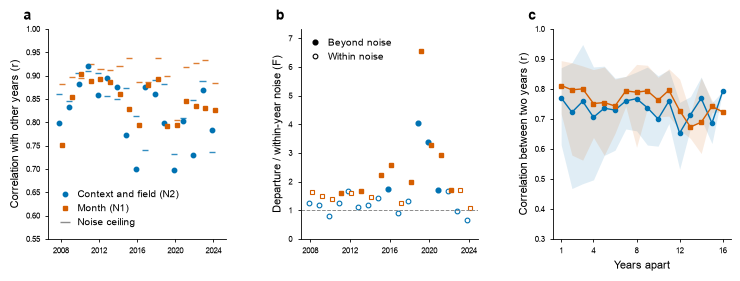

saved S6_Fig


In [11]:
calib = pd.read_csv(TAB / "annual_calibration.csv")
lagp = pd.read_csv(TAB / "annual_lag_profile.csv")
Ftab = pd.read_csv(TAB / "annual_departure_F.csv")
export_source_table(calib, "S6ab_year_vs_rest.csv")
export_source_table(lagp, "S6c_lag_profile.csv")
fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.8), gridspec_kw={"wspace": 0.42})
fig.subplots_adjust(left=0.08, right=0.99, bottom=0.15, top=0.9)
ax = axes[0]
for name, off, mk in [("N2", -0.15, "o"), ("N1", 0.15, "s")]:
    z = calib[calib.reference == name]
    ax.plot(z.year + off, z.pearson, mk, color=REF_COLOR[name], ms=3.2, label=REF_LABEL[name], zorder=3)
    ax.hlines(z.ceiling, z.year + off - 0.32, z.year + off + 0.32, color=REF_COLOR[name], lw=1.0, alpha=0.8)
ax.plot([], [], "_", color=OI["grey"], ms=7, mew=1.0, label="Noise ceiling")
ax.set_ylim(0.55, 1.0); ax.set_ylabel("Correlation with other years (r)")
ax.set_xticks(YEARS[::4]); ax.legend(loc="lower left", handlelength=1, borderaxespad=0.8)
panel_letter(ax, "a")
ax = axes[1]
for name, off, mk in [("N2", -0.15, "o"), ("N1", 0.15, "s")]:
    z = Ftab[Ftab.reference == name]; sig = z.p_holm < 0.05
    ax.plot(z.year[sig] + off, z.F[sig], mk, color=REF_COLOR[name], ms=3.4)
    ax.plot(z.year[~sig] + off, z.F[~sig], mk, mfc="white", mec=REF_COLOR[name], ms=3.4, mew=0.8)
ax.axhline(1, color=OI["grey"], lw=0.7, ls="--")
ax.set_ylabel("Departure / within-year noise (F)"); ax.set_xticks(YEARS[::4]); ax.set_ylim(0, Ftab[Ftab.reference.isin(["N2", "N1"])].F.max() * 1.12)
ax.plot([], [], "o", color="k", ms=3.4, label="Beyond noise")
ax.plot([], [], "o", mfc="white", mec="k", ms=3.4, mew=0.8, label="Within noise")
ax.legend(loc="upper left", handlelength=1, borderaxespad=0.6)
export_source_table(Ftab, "S6b_departure_F.csv")
panel_letter(ax, "b")
ax = axes[2]
for name, mk in [("N2", "o"), ("N1", "s")]:
    z = lagp[lagp.reference == name]
    ax.fill_between(z.lag_years, z.min_pearson, z.max_pearson, color=REF_COLOR[name], alpha=0.12, lw=0)
    ax.plot(z.lag_years, z.mean_pearson, mk + "-", color=REF_COLOR[name], ms=3, lw=1, label=REF_LABEL[name])
ax.set_ylim(0.3, 1.0); ax.set_xlabel("Years apart"); ax.set_ylabel("Correlation between two years (r)")
ax.set_xticks([1, 4, 8, 12, 16])
panel_letter(ax, "c")
save(fig, "S6_Fig")

S7_Fig layout check: ok


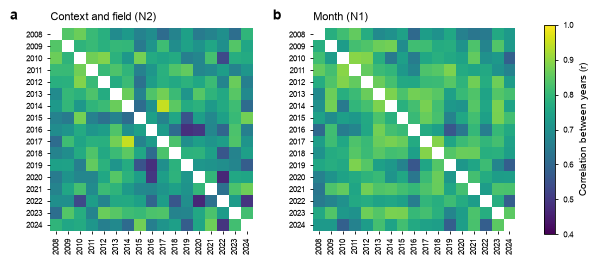

saved S7_Fig


In [12]:
# S7 Fig: year-by-year correlation matrices
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.4), gridspec_kw={"wspace": 0.3})
for ax, name, letter in zip(axes, ["N2", "N1"], "ab"):
    Mx = pd.read_csv(TAB / f"year_by_year_pearson_{name}.csv", index_col=0)
    im = ax.imshow(Mx.to_numpy(), vmin=0.4, vmax=1, cmap="viridis")
    ax.set_xticks(range(len(YEARS)), YEARS, rotation=90); ax.set_yticks(range(len(YEARS)), YEARS)
    ax.set_title(REF_LABEL[name], fontsize=8, loc="left")
    for s in ax.spines.values():
        s.set_visible(False)
    panel_letter(ax, letter, x=-0.2)
cb = fig.colorbar(im, ax=axes, shrink=0.8); cb.set_label("Correlation between years (r)", fontsize=7)
save(fig, "S7_Fig")

,reference,code_i,code_j,w2008_2018,w2021_2024
0,N1,1,2,-1.558354,-1.744379
1,N1,1,3,1.759131,1.959397
2,N1,1,4,-0.238329,0.209763
3,N1,1,5,1.210501,1.509965
4,N1,1,9,0.715177,1.360093
...,...,...,...,...,...
216,N2,27,34,0.608530,0.390922
217,N2,28,30,0.631354,0.402319
218,N2,28,33,0.791726,0.629572
219,N2,30,33,1.034577,0.889418


S8_Fig layout check: ok


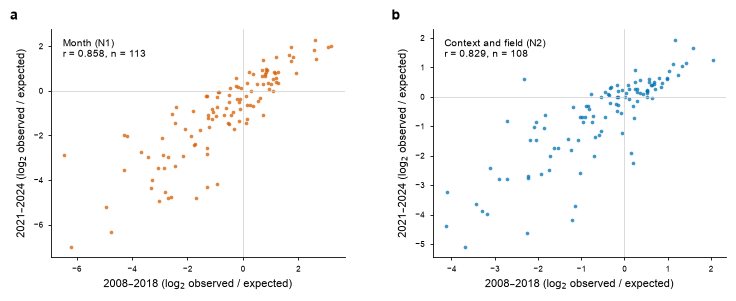

saved S8_Fig


In [13]:
# S8 Fig: two blocks of years, 2008-2018 against 2021-2024
elig_p = np.load(AGG / "eligible_pilot_frozen.npy")
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.0), gridspec_kw={"wspace": 0.3})
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.16, top=0.92)
rows = []
for ax, name, letter in zip(axes, ["N1", "N2"], "ab"):
    z = np.load(AGG / f"null_{name}.npz"); Oy = z["observed_year"].astype(float); C = z["counts"].astype(float)
    a_idx, b_idx = YEARS <= 2018, YEARS >= 2021
    Oa, Ea, Ob, Eb = Oy[a_idx].sum(0), C[:, a_idx].sum(1).mean(0), Oy[b_idx].sum(0), C[:, b_idx].sum(1).mean(0)
    sda, sdb = C[:, a_idx].sum(1).std(0, ddof=1), C[:, b_idx].sum(1).std(0, ddof=1)
    m = elig_p & (Ea >= 5) & (Eb >= 5) & (sda > 0) & (sdb > 0)
    x, y = lr(Oa, Ea)[m], lr(Ob, Eb)[m]
    ax.axhline(0, color="#CCCCCC", lw=0.5); ax.axvline(0, color="#CCCCCC", lw=0.5)
    ax.scatter(x, y, s=7, color=REF_COLOR[name], alpha=0.75, lw=0)
    ax.set_xlabel("2008–2018 (log$_2$ observed / expected)"); ax.set_ylabel("2021–2024 (log$_2$ observed / expected)")
    ax.text(0.04, 0.96, f"{REF_LABEL[name]}\nr = {np.corrcoef(x, y)[0, 1]:.3f}, n = {m.sum()}", transform=ax.transAxes, va="top", fontsize=7)
    rows += [{"reference": name, "code_i": PAIRS[h, 0], "code_j": PAIRS[h, 1], "w2008_2018": lr(Oa, Ea)[h], "w2021_2024": lr(Ob, Eb)[h]} for h in np.where(m)[0]]
    panel_letter(ax, letter)
export_source_table(pd.DataFrame(rows), "S8_two_blocks.csv")
save(fig, "S8_Fig")

,reference,year,phi,phi_lo,phi_hi
0,N2,2008,1.024301,0.894811,1.191837
1,N2,2009,0.986626,0.857171,1.131306
2,N2,2010,1.152488,0.989313,1.361597
3,N2,2011,1.102160,1.007335,1.205608
4,N2,2012,1.093077,0.962208,1.242401
5,N2,2013,1.031578,0.918584,1.150698
6,N2,2014,1.000725,0.883011,1.120407
7,N2,2015,0.921177,0.737176,1.133625
8,N2,2016,0.902580,0.751884,1.088355
9,N2,2017,1.030779,0.855094,1.236188


,pairs_with_expected,cells,D_M0,D_M1,D_M2,D_MA,perm_mean_D_M1,perm_mean_D_MA,perm_mean_D_M2,share_structure_constant,...,permutations_infinite_deviance,p_perm_D_M1,p_perm_uniform_term,X2_M1,X2_MA,df_residual_M1,pooled_dispersion_within,frequency_share_dispersion_floor,F_uniform_strength,p_F_uniform_strength
reference,,,,,,,,,,,,,,,,,,,,,
N2,291,4947,14025.063912,4349.815357,4302.826010,15126.543621,5476.937429,8448.433739,5446.375260,0.689854,...,0,1.000,0.068,5992.015287,17029.772636,4256,1.298204,0.959420,2.262229,2.800725e-03
N1,291,4947,24067.803000,5813.877089,5510.782867,15126.543621,4852.547444,8448.433739,4758.381682,0.758438,...,0,0.001,0.001,7205.216867,17029.772636,4256,1.353185,0.871696,13.999114,1.312768e-37
N2_clean,230,4947,8805.701621,2804.648192,2772.205530,8136.939814,3549.614040,5182.328124,3515.010151,0.681496,...,9,1.000,0.531,4706.462007,9580.544271,3200,1.284011,0.890779,1.579165,6.599931e-02


S9_Fig layout check: ok


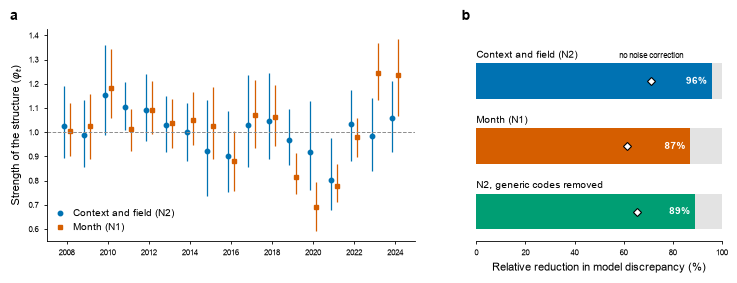

saved S9_Fig


In [14]:
phit = pd.read_csv(TAB / "unidiff_phi_by_year.csv")
dec = pd.read_csv(TAB / "loglinear_decomposition.csv").set_index("reference")
export_source_table(phit, "S9_phi.csv")
export_source_table(dec, "S9_model_fit.csv", index=True)
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.9), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.2})
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.17, top=0.9)
ax = axes[0]
for name, off, mk in [("N2", -0.15, "o"), ("N1", 0.15, "s")]:
    z = phit[phit.reference == name]
    ax.vlines(z.year + off, z.phi_lo, z.phi_hi, color=REF_COLOR[name], lw=0.9)
    ax.plot(z.year + off, z.phi, mk, color=REF_COLOR[name], ms=3.2, label=REF_LABEL[name])
ax.axhline(1, color=OI["grey"], lw=0.7, ls="--")
ax.set_ylabel("Strength of the structure ($\\varphi_t$)"); ax.set_xticks(YEARS[::2])
ax.legend(loc="lower left", handlelength=1)
panel_letter(ax, "a", x=-0.1)
ax = axes[1]
refs = ["N2", "N1", "N2_clean"]
disp = [100 * dec.loc[r, "frequency_share_dispersion_floor"] for r in refs]
raw = [100 * dec.loc[r, "frequency_share_raw"] for r in refs]
y = np.arange(len(refs))[::-1]
ax.barh(y, disp, color=[REF_COLOR[r] for r in refs], height=0.55)
ax.barh(y, [100 - v for v in disp], left=disp, color="#E3E3E3", height=0.55)
ax.plot(raw, y, "D", mfc="white", mec="k", ms=4, mew=0.8)
for yy, v, r in zip(y, disp, refs):
    ax.text(v - 2, yy, f"{v:.0f}%", ha="right", va="center", fontsize=7, color="white", fontweight="bold")
    ax.text(0, yy + 0.33, REF_LABEL[r], ha="left", va="bottom", fontsize=7)
ax.text(raw[0], y[0] + 0.33, "no noise correction", ha="center", va="bottom", fontsize=6)
ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.set_xlim(0, 100); ax.set_ylim(-0.45, len(refs) - 0.2)
ax.set_xlabel("Relative reduction in model discrepancy (%)")
panel_letter(ax, "b", x=-0.06)
save(fig, "S9_Fig")

,reference,year,pairs,pearson,spearman,sign_agreement,strong_pairs,strong_sign_agreement,strong_excess,strong_deficit,actions_multi_pairs_observed
0,N1,2008,59,0.750428,0.863530,0.966102,47,0.978723,14,33,1601
1,N1,2009,54,0.854826,0.882142,0.944444,43,0.976744,13,30,1114
2,N1,2010,39,0.903508,0.889069,0.923077,31,0.967742,10,21,889
3,N1,2011,82,0.889183,0.903310,0.853659,60,0.950000,20,40,2283
4,N1,2012,62,0.892019,0.938103,0.983871,48,1.000000,16,32,1257
...,...,...,...,...,...,...,...,...,...,...,...
97,N1_k2,2020,27,0.849413,0.765568,0.740741,16,0.812500,6,10,649
98,N1_k2,2021,22,0.874618,0.941276,0.909091,15,1.000000,3,12,677
99,N1_k2,2022,19,0.848068,0.859649,0.842105,13,1.000000,1,12,608
100,N1_k2,2023,10,0.688083,0.818182,1.000000,7,1.000000,1,6,429


S10_Fig layout check: ok


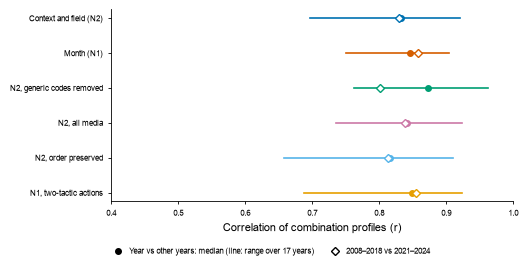

saved S10_Fig


In [15]:
# S10 Fig: robustness across references (median and range of year-vs-rest r; two blocks of years)
yvr = pd.read_csv(TAB / "annual_year_vs_rest.csv"); pil = pd.read_csv(TAB / "pilot_windows_reproduced.csv").set_index("reference")
refs = ["N2", "N1", "N2_clean", "N2_allmedia", "N2_order", "N1_k2"]
fig, ax = plt.subplots(figsize=(6.0, 3.0))
fig.subplots_adjust(left=0.3, right=0.97, bottom=0.33, top=0.97)
for i, r in enumerate(refs):
    z = yvr[yvr.reference == r]
    ax.plot([z.pearson.min(), z.pearson.max()], [i, i], color=REF_COLOR[r], lw=1.2)
    ax.plot(z.pearson.median(), i, "o", color=REF_COLOR[r], ms=4)
    ax.plot(pil.loc[r, "pearson"], i, "D", mfc="white", mec=REF_COLOR[r], ms=4)
ax.set_yticks(range(len(refs)), [REF_LABEL[r] for r in refs]); ax.invert_yaxis()
ax.set_xlabel("Correlation of combination profiles (r)"); ax.set_xlim(0.4, 1)
ax.plot([], [], "o", color="k", ms=4, label="Year vs other years: median (line: range over 17 years)")
ax.plot([], [], "D", mfc="white", mec="k", ms=4, label="2008–2018 vs 2021–2024")
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.2), ncol=2, fontsize=6, handlelength=1)
export_source_table(yvr, "S10_robustness.csv")
save(fig, "S10_Fig")